In [1]:
import os
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models.feature_extraction import create_feature_extractor

from tqdm import tqdm

In [2]:
!gdown "1_SSG-CeOv9ORh_1fTqmibCZ8Xu28tk0S"

Downloading...
From (original): https://drive.google.com/uc?id=1_SSG-CeOv9ORh_1fTqmibCZ8Xu28tk0S
From (redirected): https://drive.google.com/uc?id=1_SSG-CeOv9ORh_1fTqmibCZ8Xu28tk0S&confirm=t&uuid=6a5d0283-3a47-4791-bedc-393784ccd0f7
To: /content/before clean dataset.zip
100% 625M/625M [00:10<00:00, 61.9MB/s]


In [3]:
!unzip -q "/content/before clean dataset.zip" -d /content/beforeCleanDataset

In [4]:
import shutil

# Specify the path to the folder you want to delete
folder_to_delete = '/content/beforeCleanDataset/before clean dataset/Alticini'
folder_to_delete2 = '/content/beforeCleanDataset/before clean dataset/Miridae'

# IMPORTANT: Be very careful with this command as it permanently deletes the folder and its contents.
# Uncomment the line below to execute the deletion:
shutil.rmtree(folder_to_delete)
shutil.rmtree(folder_to_delete2)

print(f"Folder '{folder_to_delete}, {folder_to_delete2}' (and its contents) would be deleted if the shutil.rmtree line was uncommented.")
print("Please replace 'path/to/your/folder' with the actual folder you wish to delete and uncomment the shutil.rmtree line to proceed.")

Folder '/content/beforeCleanDataset/before clean dataset/Alticini, /content/beforeCleanDataset/before clean dataset/Miridae' (and its contents) would be deleted if the shutil.rmtree line was uncommented.
Please replace 'path/to/your/folder' with the actual folder you wish to delete and uncomment the shutil.rmtree line to proceed.


In [5]:
!pip install split-folders

In [6]:
import splitfolders

# input_folder: the path where your 12 class folders are
# output_folder: where the train/val/test folders will be created
splitfolders.ratio("/content/beforeCleanDataset/before clean dataset", output="/content/dataset_split",
                   seed=42, ratio=(.8, .1, .1), move=False)

Copying files: 26238 files [00:08, 3029.73 files/s]


# **Step 1: Setup and Environment**

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 2: Define the WaveLet + MobileNet

In [8]:
import torch
import torch.nn as nn
import torchvision.models as models

class HaarDWT2D(nn.Module):
    """Lossless 2D Haar Wavelet Decomposition."""
    def __init__(self):
        super(HaarDWT2D, self).__init__()
        self.register_buffer('pL', torch.tensor([0.5, 0.5]))
        self.register_buffer('pH', torch.tensor([0.5, -0.5]))

    def forward(self, x):
        B, C, H, W = x.shape
        x_grouped = x.view(B * C, 1, H, W)

        k_LL = torch.outer(self.pL, self.pL).view(1, 1, 2, 2)
        k_LH = torch.outer(self.pL, self.pH).view(1, 1, 2, 2)
        k_HL = torch.outer(self.pH, self.pL).view(1, 1, 2, 2)
        k_HH = torch.outer(self.pH, self.pH).view(1, 1, 2, 2)

        kernels = torch.cat([k_LL, k_LH, k_HL, k_HH], dim=0).to(x.device)
        sub_bands = nn.functional.conv2d(x_grouped, kernels, stride=2)
        sub_bands = sub_bands.view(B, C, 4, H // 2, W // 2)

        LL = sub_bands[:, :, 0, :, :]
        details = sub_bands[:, :, 1:, :, :].permute(0, 1, 2, 3, 4).reshape(B, C * 3, H // 2, W // 2)
        return LL, details

class WaveletMobileNetBlock(nn.Module):
    """Replaces standard lossy strided layers inside MobileNet V2."""
    def __init__(self, in_channels, out_channels, expand_ratio):
        super(WaveletMobileNetBlock, self).__init__()
        self.hidden_dim = int(in_channels * expand_ratio)

        # Main Spatial Stream
        self.spatial_expand = nn.Sequential(
            nn.Conv2d(in_channels, self.hidden_dim, 1, 1, 0, bias=False),
            nn.BatchNorm2d(self.hidden_dim),
            nn.ReLU6(inplace=True)
        )
        self.spatial_depthwise = nn.Sequential(
            nn.Conv2d(self.hidden_dim, self.hidden_dim, 3, 1, 1, groups=self.hidden_dim, bias=False),
            nn.BatchNorm2d(self.hidden_dim),
            nn.ReLU6(inplace=True)
        )
        self.spatial_downsample = nn.AvgPool2d(kernel_size=2, stride=2)

        # Parallel Wavelet Stream
        self.dwt = HaarDWT2D()
        self.wavelet_project = nn.Sequential(
            nn.Conv2d(in_channels * 3, self.hidden_dim, 1, 1, 0, bias=False),
            nn.BatchNorm2d(self.hidden_dim),
            nn.ReLU6(inplace=True)
        )

        # Fusion Projection
        self.linear_project = nn.Sequential(
            nn.Conv2d(self.hidden_dim * 2, out_channels, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_channels)
        )

    def forward(self, x):
        _, wavelet_details = self.dwt(x)
        wavelet_feats = self.wavelet_project(wavelet_details)

        spatial_feats = self.spatial_expand(x)
        spatial_feats = self.spatial_depthwise(spatial_feats)
        spatial_feats = self.spatial_downsample(spatial_feats)

        fused_feats = torch.cat([spatial_feats, wavelet_feats], dim=1)
        return self.linear_project(fused_feats)

def get_wavelet_mobilenet_v2(num_classes=12):
    # Instantiate pretrained MobileNetV2
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

    # Locate the bottlenecks where MobileNet downsamples resolution.
    # In MobileNetV2 features stack:
    # index [4] shifts stride from 1 -> 2 (24 channels -> 32 channels)
    # index [7] shifts stride from 1 -> 2 (32 channels -> 64 channels)

    model.features[4] = WaveletMobileNetBlock(in_channels=24, out_channels=32, expand_ratio=6)
    model.features[7] = WaveletMobileNetBlock(in_channels=32, out_channels=64, expand_ratio=6)

    # Re-map classifier output to match your dataset classes
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model.to(device)



In [9]:
# Instantiate the updated model
model = get_wavelet_mobilenet_v2(num_classes=10)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 182MB/s]


# **Step 4: Data Augmentation and Loading**

In [10]:
# Simple Gaussian Noise
class AddGaussianNoise(object):
    def __init__(self, mean=0., std=1.):
        self.std = std
        self.mean = mean
    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

# Exact same methods proposed by paper
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # Image normalization
    transforms.RandomHorizontalFlip(), # Basic
    transforms.RandomRotation([0, 270]), # Spin
    # transforms.ColorJitter(brightness=0.2, contrast=0.2), # Color jitter
    # Note: Zoom and Gaussian noise usually require custom logic or specific
    # torchvision versions. Here we use standard equivalents.
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)), # Zoom simulation
    # AddGaussianNoise(0., 0.1), # Gaussian noise
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Assuming dataset is organized in class folders
train_dataset = datasets.ImageFolder('/content/dataset_split/train', transform=train_transforms)
val_dataset = datasets.ImageFolder('/content/dataset_split/val', transform=val_transforms)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

# **Step 5: Training Setup**

In [11]:
criterion = nn.CrossEntropyLoss()

# Separate the parameters into two groups to handle pre-trained weights safely
wavelet_custom_params = []
backbone_pretrained_params = []

for name, param in model.named_parameters():
    # If the layer belongs to our newly injected blocks or classifier, group them here
    if 'wavelet' in name or 'classifier' in name:
        wavelet_custom_params.append(param)
    else:
        backbone_pretrained_params.append(param)

# Assign conservative learning rates to protect pre-trained features
optimizer = optim.Adam([
    {'params': backbone_pretrained_params, 'lr': 1e-5}, # Keep slow so pre-trained shapes don't distort
    {'params': wavelet_custom_params, 'lr': 1e-4}      # Allow custom frequency-fusion parts to learn faster
])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2)

# **Step 6: Training and Evaluation Loops**

In [12]:
from tqdm.notebook import tqdm
import time

def train_model(model, train_loader, val_loader, epochs=6):
    best_acc = 0.0
    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    print('Training begins...')
    for epoch in range(epochs):
        start_time = time.time()

        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Create a progress bar for the training loader
        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", unit="batch")

        for inputs, labels in train_pbar:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

            # Show the current loss in the progress bar
            train_pbar.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100 * correct_train / total_train

        # --- Validation Phase ---
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        # Optional: Add a second progress bar for validation (disappears after finish)
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", unit="batch", leave=False)

        with torch.no_grad():
            for inputs, labels in val_pbar:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)

                # --- Calculate Validation Loss ---
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)
                # ---------------------------------

                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(val_loader.dataset)
        val_acc = 100 * correct_val / total_val

        # Update Learning Rate
        scheduler.step(val_acc)

        # Save History
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)

        epoch_duration = time.time() - start_time
        print(f'Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Val Acc: {val_acc:.2f}% | Time: {epoch_duration:.0f}s')

        # Save Best Model
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_pcsa_model.pth')

    return history

In [ ]:
# Launch training
history = train_model(model, train_loader, val_loader, epochs=10)

Training begins...


Epoch 1/10 [Train]:   0%|          | 0/656 [00:00<?, ?batch/s]

Epoch 1/10 [Val]:   0%|          | 0/82 [00:00<?, ?batch/s]

Epoch 1/10 | Loss: 2.2461 | Train Acc: 16.61% | Val Acc: 20.34% | Time: 185s


Epoch 2/10 [Train]:   0%|          | 0/656 [00:00<?, ?batch/s]

Epoch 2/10 [Val]:   0%|          | 0/82 [00:00<?, ?batch/s]

Epoch 2/10 | Loss: 2.1257 | Train Acc: 22.37% | Val Acc: 24.23% | Time: 183s


Epoch 3/10 [Train]:   0%|          | 0/656 [00:00<?, ?batch/s]

# **Step 7: Visualization (Graph Types)**

In [ ]:
def plot_training_history(history):
    epochs = range(1, len(history['train_loss']) + 1)

    # Create a figure with two subplots side-by-side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # --- Plot 1: Accuracy ---
    ax1.plot(epochs, history['train_acc'], label='Training Accuracy', color='blue', lw=2)
    ax1.plot(epochs, history['val_acc'], label='Validation Accuracy', color='red', linestyle='--', lw=2)
    ax1.set_title('Training and Validation Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy (%)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # --- Plot 2: Loss ---
    ax2.plot(epochs, history['train_loss'], label='Training Loss', color='blue', lw=2)
    ax2.plot(epochs, history['val_loss'], label='Validation Loss', color='red', linestyle='--', lw=2)
    ax2.set_title('Training and Validation Loss')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss Value')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

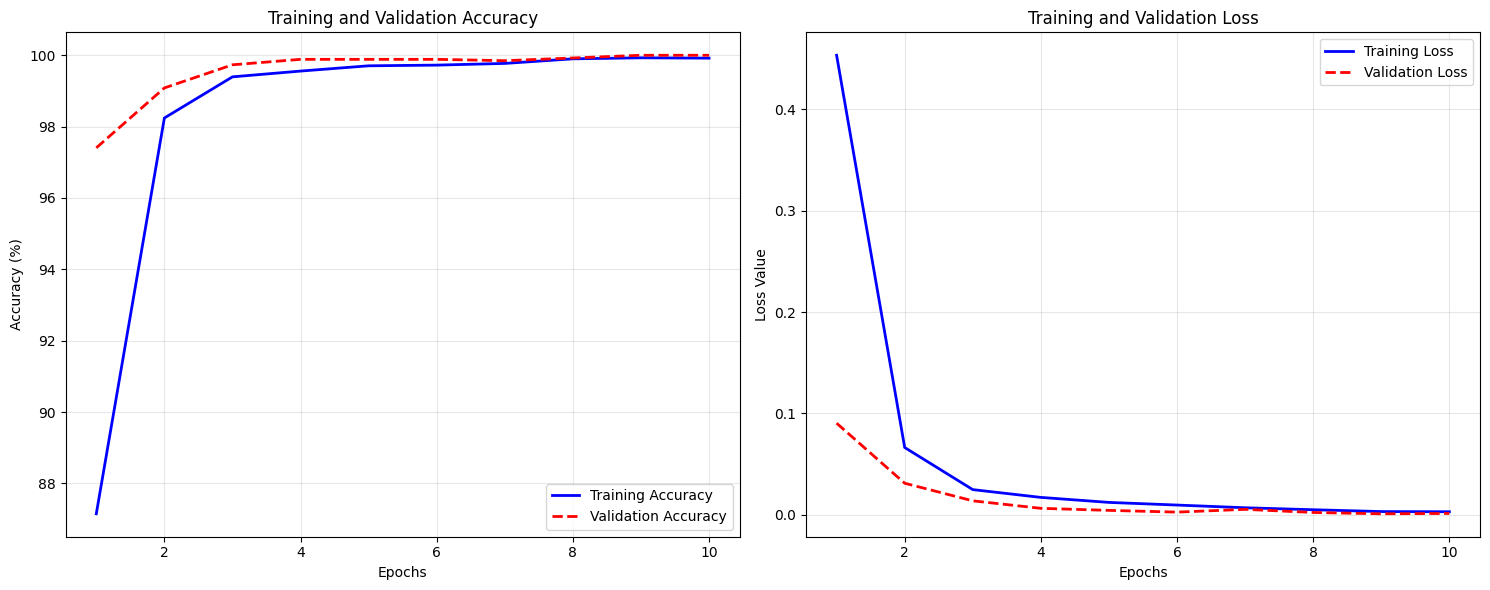

In [ ]:
plot_training_history(history)

# **Step 8: Confusion Matrix and Scoring**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_final_model(model, test_loader, class_names):
    model.load_state_dict(torch.load('best_pcsa_model.pth'))
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Detailed Scoring (P, R, F1) [cite: 180]
    print("\nClassification Report (Precision, Recall, F1):")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix for 12 Classes')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

In [ ]:
import seaborn as sns

# Create the test loader
test_dataset = datasets.ImageFolder('/content/dataset_split/test', transform=val_transforms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# Get the class names directly from the dataset
class_names = test_dataset.classes


Classification Report (Precision, Recall, F1):
                           precision    recall  f1-score   support

        Acalymma_vittatum       1.00      1.00      1.00       219
          Achatina_fulica       1.00      1.00      1.00       256
              Ampelophaga       1.00      1.00      1.00       279
Leptinotarsa_decemlineata       1.00      1.00      1.00       268
      Potosiabre vitarsis       1.00      1.00      1.00       265
                   Thrips       1.00      1.00      1.00       227
              grasshopper       1.00      1.00      1.00       277
              leaf beetle       1.00      1.00      1.00       276
    legume blister beetle       1.00      1.00      1.00       294
             lytta polita       1.00      1.00      1.00       267

                 accuracy                           1.00      2628
                macro avg       1.00      1.00      1.00      2628
             weighted avg       1.00      1.00      1.00      2628



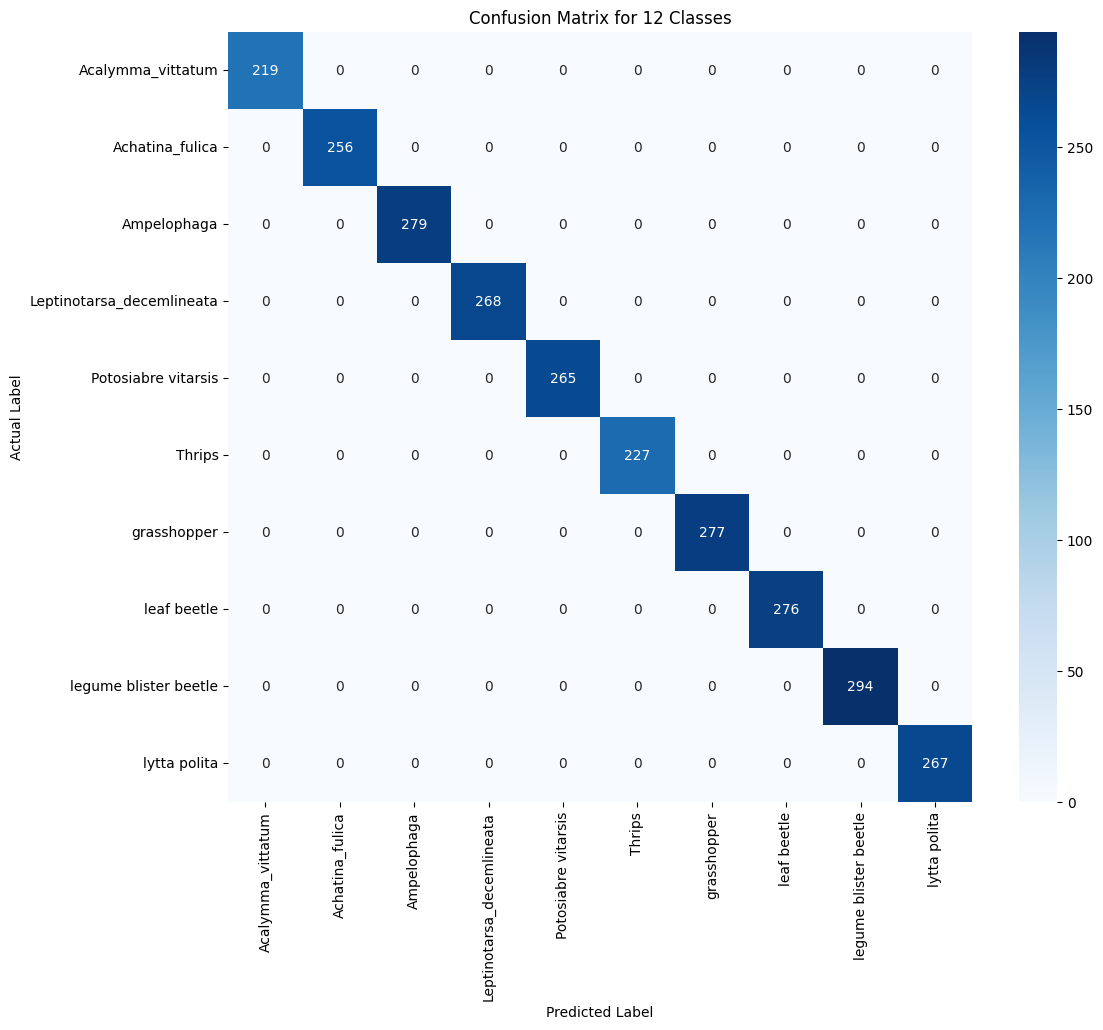

In [ ]:
# This will load 'best_pcsa_model.pth', predict the test set, and plot the results
evaluate_final_model(model, test_loader, class_names)